# **Redes Neuronales 2**
## Práctica 7: Redes neuronales en grafos

**Temas:**
- El dataset Cora: clasificación de nodos en un grafo de citas.
- Convoluciones en grafos: GCN (espacial) y ChebConv (espectral polinómica).
- Entrenamiento transductivo con máscaras de train/val/test.

## Clasificación de artículos científicos: el dataset Cora

**Cora** es un grafo de citas: cada nodo es un artículo científico y cada arista una cita entre artículos. Cada nodo tiene características basadas en las palabras del artículo (bolsa de palabras de 1433 términos) y una etiqueta con su área (7 clases): Case_Based, Genetic_Algorithms, Neural_Networks, Probabilistic_Methods, Reinforcement_Learning, Rule_Learning y Theory.

Más datos: https://arxiv.org/abs/1603.08861

In [2]:
# En Colab hace falta instalar dependencias (local: ya instaladas)
import importlib, subprocess, sys
for pkg, mod in [('torch_geometric', 'torch_geometric')]:
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

d:\facuult\REDES_NEURONALES_II\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv, ChebConv

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset = Planetoid(root="./data/Cora", name="Cora")
data = dataset[0]          # Cora es UN solo grafo

print(f"Número de nodos: {data.num_nodes}")
print(f"Número de aristas: {data.num_edges}")
print(f"Características por nodo: {dataset.num_node_features}")
print(f"Número de clases: {dataset.num_classes}")
print(f"¿Es dirigido?: {data.is_directed()}")
print(f"x: {tuple(data.x.shape)} | edge_index: {tuple(data.edge_index.shape)} | y: {tuple(data.y.shape)}")

Processing...


Número de nodos: 2708
Número de aristas: 10556
Características por nodo: 1433
Número de clases: 7
¿Es dirigido?: False
x: (2708, 1433) | edge_index: (2, 10556) | y: (2708,)


Done!


Dataset
x= [2708, 1433] son 2708 nodos donde cada uno es un paper cientifico. Cada paper tiene 1433 bolsa de palabras de un vocabulario (1 si aparece 0 si no aparece)
edge_index= [2, 10556] son aristas

In [5]:
print(data.edge_index)

tensor([[ 633, 1862, 2582,  ...,  598, 1473, 2706],
        [   0,    0,    0,  ..., 2707, 2707, 2707]])


### Máscaras de train, val y test

El aprendizaje es **transductivo**: la red ve el grafo completo (características y aristas), pero las **etiquetas** solo se usan en los nodos de la máscara correspondiente.

¿De dónde sale este split? Buscar en la documentación de [`Planetoid`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.Planetoid.html).

In [7]:
print("nodos de train:", data.train_mask.sum().item())
print("nodos de val:  ", data.val_mask.sum().item())
print("nodos de test: ", data.test_mask.sum().item())

nodos de train: 140
nodos de val:   500
nodos de test:  1000


---
## Ejercicio 1: crear la red

Definir una red de **dos capas convolucionales en grafo** con 16 características intermedias, activación ReLU y dropout entre capas. La clase debe aceptar el tipo de capa: `GCNConv` (convolución espacial de primer orden) o `ChebConv` con $K=3$ (aproximación polinómica de Chebyshev de la convolución espectral).

In [8]:
# ====================== COMPLETAR ======================
class GNN(torch.nn.Module):
    """Red de 2 capas convolucionales en grafo.

    conv: "gcn" -> GCNConv (espacial, 1er orden)
          "cheb" -> ChebConv con K=3 (aproximación polinómica de Chebyshev)
    """
    def __init__(self, in_channels, hidden_channels, out_channels, conv="gcn", K=3, dropout=0.5):
        super().__init__()
        if conv == "gcn":
            self.conv1 = GCNConv(in_channels, hidden_channels)
            self.conv2 = GCNConv(hidden_channels, out_channels)
        elif conv == "cheb":
            self.conv1 = ChebConv(in_channels, hidden_channels, K=K)
            self.conv2 = ChebConv(hidden_channels, out_channels, K=K)
        else:
            raise ValueError("conv debe ser 'gcn' o 'cheb'")
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)


# Prueba rápida
model = GNN(dataset.num_node_features, 16, dataset.num_classes, conv="gcn").to(device)
data = data.to(device)
print(model)
out = model(data.x, data.edge_index)
print("Salida:", tuple(out.shape))  # (2708, 7)

model_cheb = GNN(dataset.num_node_features, 16, dataset.num_classes, conv="cheb", K=3).to(device)
print(model_cheb)
# ========================================================


GNN(
  (conv1): GCNConv(1433, 16)
  (conv2): GCNConv(16, 7)
)
Salida: (2708, 7)
GNN(
  (conv1): ChebConv(1433, 16, K=3, normalization=sym)
  (conv2): ChebConv(16, 7, K=3, normalization=sym)
)


---
## Ejercicio 2: entrenar la red

Usar **Adam** (`lr=0.01`, `weight_decay=5e-4`), la **NLLLoss** como pérdida (la red devuelve `log_softmax`) y **early stopping** monitoreando la accuracy de validación (quedarse con el mejor modelo). Entrenar hasta 200 épocas y reportar la accuracy de test del mejor modelo.

Época  20 | loss 0.3682 | train 1.000 | val 0.768
Época  40 | loss 0.1256 | train 1.000 | val 0.764
Época  60 | loss 0.0508 | train 1.000 | val 0.774
Época  80 | loss 0.0579 | train 1.000 | val 0.784
Época 100 | loss 0.0600 | train 1.000 | val 0.764
Época 120 | loss 0.0514 | train 1.000 | val 0.776
Época 140 | loss 0.0655 | train 1.000 | val 0.770
Época 160 | loss 0.0465 | train 1.000 | val 0.754
Época 180 | loss 0.0611 | train 1.000 | val 0.764
Época 200 | loss 0.0382 | train 1.000 | val 0.764
Mejor época: 77 | val acc: 0.786
GCN -> train 1.000 | val 0.786 | test 0.803


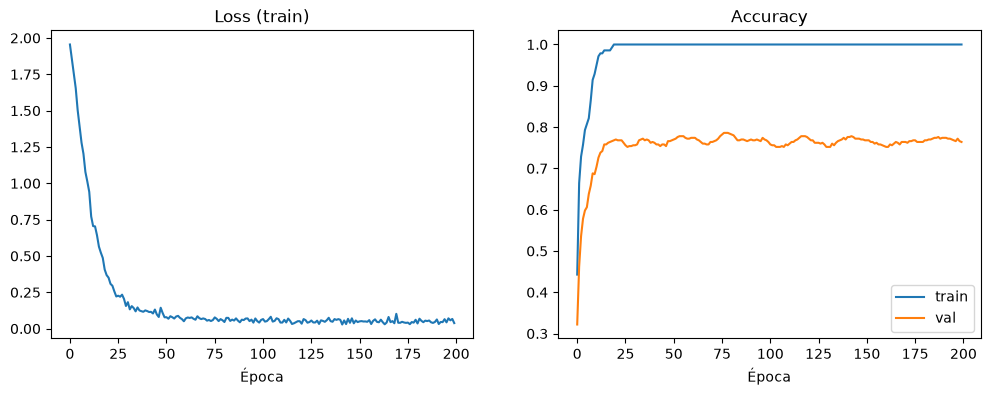

In [9]:
# ====================== COMPLETAR ======================
import copy

def entrenar(model, data, epochs=200, lr=0.01, weight_decay=5e-4, patience=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = torch.nn.NLLLoss()

    best_val_acc = 0
    best_state = None
    best_epoch = 0
    hist = {"loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(1, epochs + 1):
        # --- entrenamiento ---
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)                      # forward sobre TODO el grafo
        loss = criterion(out[data.train_mask], data.y[data.train_mask])  # pérdida solo en train
        loss.backward()
        optimizer.step()

        # --- evaluación ---
        train_acc, val_acc, _ = evaluar(model, data)
        hist["loss"].append(loss.item())
        hist["train_acc"].append(train_acc)
        hist["val_acc"].append(val_acc)

        # --- early stopping: guardo el mejor modelo según val ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
        elif patience is not None and epoch - best_epoch >= patience:
            print(f"Early stopping en época {epoch}")
            break

        if epoch % 20 == 0:
            print(f"Época {epoch:3d} | loss {loss.item():.4f} | train {train_acc:.3f} | val {val_acc:.3f}")

    model.load_state_dict(best_state)   # me quedo con el mejor modelo
    print(f"Mejor época: {best_epoch} | val acc: {best_val_acc:.3f}")
    return hist


@torch.no_grad()
def evaluar(model, data):
    model.eval()
    pred = model(data.x, data.edge_index).argmax(dim=1)
    accs = []
    for mask in [data.train_mask, data.val_mask, data.test_mask]:
        accs.append((pred[mask] == data.y[mask]).float().mean().item())
    return accs   # [train, val, test]


# --- Entrenar la GCN ---
torch.manual_seed(42)
data = data.to(device)
model_gcn = GNN(dataset.num_node_features, 16, dataset.num_classes, conv="gcn").to(device)
hist_gcn = entrenar(model_gcn, data, epochs=200)

train_acc, val_acc, test_acc = evaluar(model_gcn, data)
print(f"GCN -> train {train_acc:.3f} | val {val_acc:.3f} | test {test_acc:.3f}")

# --- Curvas ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_gcn["loss"]); ax[0].set_title("Loss (train)"); ax[0].set_xlabel("Época")
ax[1].plot(hist_gcn["train_acc"], label="train")
ax[1].plot(hist_gcn["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Época"); ax[1].legend()
plt.show()
# ========================================================


---
## Ejercicio 3: matriz de confusión sobre test

Calcular y graficar la matriz de confusión sobre los nodos de test (`sklearn.metrics.confusion_matrix`). ¿Qué clases se confunden más?

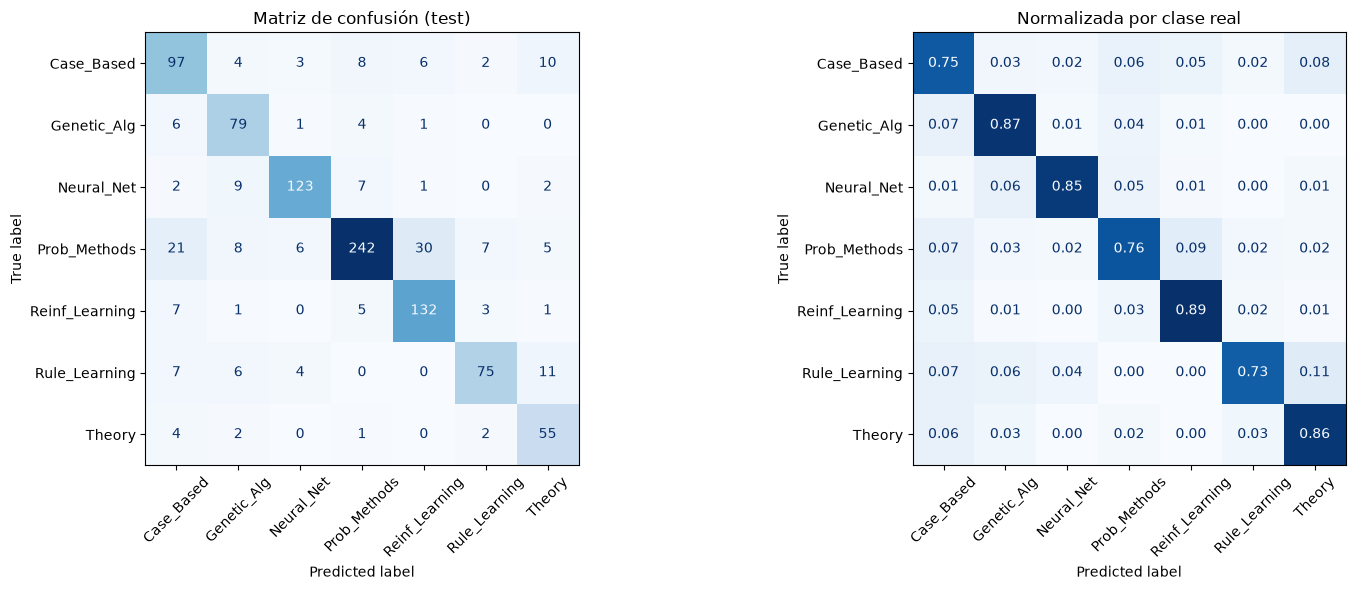

Confusiones más frecuentes (real -> predicha):
  Prob_Methods    -> Reinf_Learning : 30 nodos
  Prob_Methods    -> Case_Based     : 21 nodos
  Rule_Learning   -> Theory         : 11 nodos
  Case_Based      -> Theory         : 10 nodos
  Neural_Net      -> Genetic_Alg    : 9 nodos

Accuracy test: 0.803


In [10]:
# ====================== COMPLETAR ======================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

clases = ["Case_Based", "Genetic_Alg", "Neural_Net", "Prob_Methods",
          "Reinf_Learning", "Rule_Learning", "Theory"]

# Predicciones del mejor modelo sobre test
model_gcn.eval()
with torch.no_grad():
    pred = model_gcn(data.x, data.edge_index).argmax(dim=1)

y_true = data.y[data.test_mask].cpu().numpy()
y_pred = pred[data.test_mask].cpu().numpy()

cm = confusion_matrix(y_true, y_pred)

# --- Gráfico: absoluta y normalizada por fila (recall por clase) ---
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay(cm, display_labels=clases).plot(
    ax=ax[0], cmap="Blues", xticks_rotation=45, colorbar=False)
ax[0].set_title("Matriz de confusión (test)")

cm_norm = confusion_matrix(y_true, y_pred, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(
    ax=ax[1], cmap="Blues", xticks_rotation=45, colorbar=False, values_format=".2f")
ax[1].set_title("Normalizada por clase real")
plt.tight_layout()
plt.show()

# --- Pares de clases que más se confunden (fuera de la diagonal) ---
off = cm.copy()
np.fill_diagonal(off, 0)
idx = np.dstack(np.unravel_index(np.argsort(-off, axis=None), off.shape))[0]
print("Confusiones más frecuentes (real -> predicha):")
for i, j in idx[:5]:
    print(f"  {clases[i]:15s} -> {clases[j]:15s}: {off[i, j]} nodos")

print(f"\nAccuracy test: {np.trace(cm) / cm.sum():.3f}")
# ========================================================


---
## Ejercicio 4: GCN vs. ChebConv

Repetir el entrenamiento con `ChebConv` (K=3) y comparar la accuracy de test con la GCN. ¿Qué relación hay entre ambas capas? (Pensar en la aproximación polinómica de la convolución espectral vista en la teoría: GCN ≈ Chebyshev de primer orden con simplificaciones.)

In [11]:
# ====================== COMPLETAR ======================
torch.manual_seed(42)
model_cheb = GNN(dataset.num_node_features, 16, dataset.num_classes, conv="cheb", K=3).to(device)
print(model_cheb)

hist_cheb = entrenar(model_cheb, data, epochs=200)

train_acc, val_acc, test_acc = evaluar(model_cheb, data)
print(f"ChebConv -> train {train_acc:.3f} | val {val_acc:.3f} | test {test_acc:.3f}")
# ========================================================


GNN(
  (conv1): ChebConv(1433, 16, K=3, normalization=sym)
  (conv2): ChebConv(16, 7, K=3, normalization=sym)
)
Época  20 | loss 0.0390 | train 1.000 | val 0.766
Época  40 | loss 0.0292 | train 1.000 | val 0.764
Época  60 | loss 0.0089 | train 1.000 | val 0.768
Época  80 | loss 0.0121 | train 1.000 | val 0.776
Época 100 | loss 0.0152 | train 1.000 | val 0.788
Época 120 | loss 0.0086 | train 1.000 | val 0.778
Época 140 | loss 0.0093 | train 1.000 | val 0.788
Época 160 | loss 0.0067 | train 1.000 | val 0.804
Época 180 | loss 0.0046 | train 1.000 | val 0.806
Época 200 | loss 0.0120 | train 1.000 | val 0.790
Mejor época: 179 | val acc: 0.806
ChebConv -> train 1.000 | val 0.806 | test 0.811


Modelo     |  Params |    Val |   Test
GCN        |   23063 |  0.786 |  0.803
ChebConv   |   69143 |  0.806 |  0.811

Test acc en 10 semillas:
  gcn  : 0.803 ± 0.009
  cheb : 0.806 ± 0.008


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

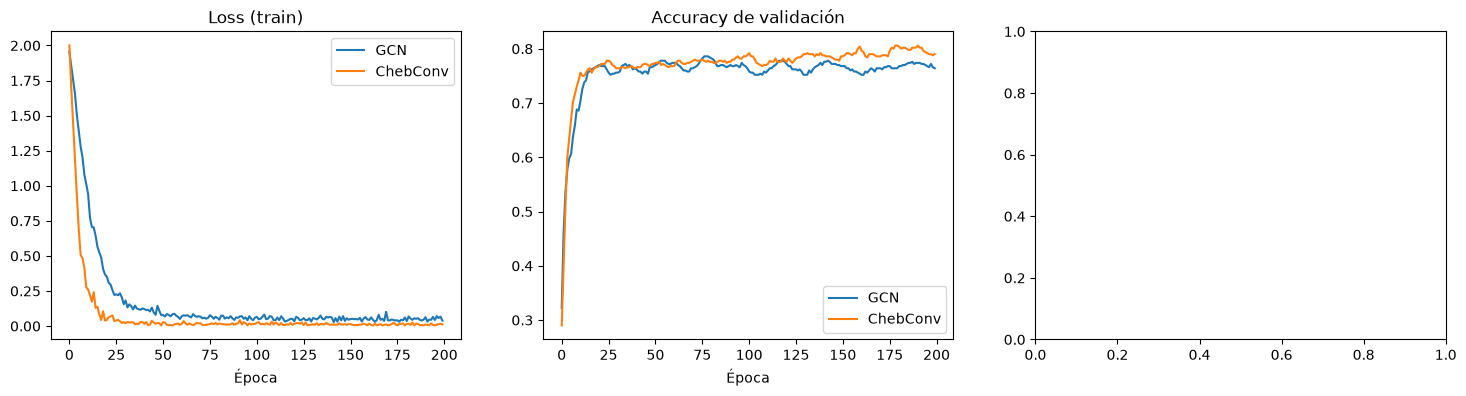

In [12]:
import contextlib, io

def contar_params(model):
    return sum(p.numel() for p in model.parameters())

# --- 1) Resultados de una corrida (seed 42) ---
_, val_gcn, test_gcn = evaluar(model_gcn, data)
_, val_cheb, test_cheb = evaluar(model_cheb, data)
print(f"{'Modelo':10s} | {'Params':>7s} | {'Val':>6s} | {'Test':>6s}")
print(f"{'GCN':10s} | {contar_params(model_gcn):7d} | {val_gcn:6.3f} | {test_gcn:6.3f}")
print(f"{'ChebConv':10s} | {contar_params(model_cheb):7d} | {val_cheb:6.3f} | {test_cheb:6.3f}")

# --- 2) Varias semillas para que la comparación sea robusta ---
seeds = range(10)
resultados = {"gcn": [], "cheb": []}
for conv in ["gcn", "cheb"]:
    for s in seeds:
        torch.manual_seed(s)
        m = GNN(dataset.num_node_features, 16, dataset.num_classes, conv=conv, K=3).to(device)
        with contextlib.redirect_stdout(io.StringIO()):   # silencia los prints de entrenar()
            entrenar(m, data, epochs=200)
        resultados[conv].append(evaluar(m, data)[2])

print(f"\nTest acc en {len(seeds)} semillas:")
for conv, accs in resultados.items():
    print(f"  {conv:5s}: {np.mean(accs):.3f} ± {np.std(accs):.3f}")

# --- 3) Gráficos ---
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(hist_gcn["loss"], label="GCN")
ax[0].plot(hist_cheb["loss"], label="ChebConv")
ax[0].set_title("Loss (train)"); ax[0].set_xlabel("Época"); ax[0].legend()

ax[1].plot(hist_gcn["val_acc"], label="GCN")
ax[1].plot(hist_cheb["val_acc"], label="ChebConv")
ax[1].set_title("Accuracy de validación"); ax[1].set_xlabel("Época"); ax[1].legend()

ax[2].boxplot([resultados["gcn"], resultados["cheb"]], labels=["GCN", "ChebConv (K=3)"])
ax[2].set_title(f"Test acc ({len(seeds)} semillas)")
plt.tight_layout()
plt.show()
